# **Brazil**

In [ ]:
BR_With_Coordinate = [occ.search(taxonKey = keys, country='BR', hasCoordinate=True, limit=0)['count']]
print(f'Brazil: \nRecords with coordinates: {BR_With_Coordinate}')

BR_Without_Coordinate = [occ.search(taxonKey = keys, country='BR', hasCoordinate=False, limit=0)['count']]
print(f'Records without coordinates: {BR_Without_Coordinate}')


Brazil: 
Records with coordinates: [1127]
Records without coordinates: [1362]


In [ ]:
#Get all records with coordinates
keep_going = True
index = 0
lim = 300
BRDF = []
while keep_going:
    res = occ.search(taxonKey=keys,
                 country='BR',
                 hasCoordinate=True,
                 offset=index,
                 limit=lim)

    count = res['count']
    print(len(res['results']))

    index =index+lim
    print(index)
    print("--------------------")

#Convert results into a dataframe
    df_BR = pd.DataFrame.from_records(res['results'])
    BRDF.append(df_BR)

    if index >= int(count):
        keep_going = False

#Concatenate all dataframes into one
df_BR = pd.concat(BRDF, ignore_index=True)

300
300
--------------------
300
600
--------------------
300
900
--------------------
227
1200
--------------------


In [ ]:
df_BR.shape

(1127, 117)

In [ ]:
df_BR.head(3)

,key,datasetKey,publishingOrgKey,installationKey,hostingOrganizationKey,publishingCountry,protocol,lastCrawled,lastParsed,crawlId,...,identificationRemarks,dateIdentified,taxonRemarks,georeferencedBy,datasetID,georeferencedDate,nomenclaturalCode,georeferenceProtocol,organismID,higherClassification
0,3818013002,d8cd16ba-bb74-4420-821e-083f2bac17c2,ada9d123-ddb4-467d-8891-806ea8d94230,17a83780-3060-4851-9d6f-029d5fcb81c9,fbca90e3-8aed-48b1-84e3-369afbd000ce,GB,EML,2025-07-12T12:04:34.340+00:00,2025-07-12T12:34:38.663+00:00,229,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3818025966,d8cd16ba-bb74-4420-821e-083f2bac17c2,ada9d123-ddb4-467d-8891-806ea8d94230,17a83780-3060-4851-9d6f-029d5fcb81c9,fbca90e3-8aed-48b1-84e3-369afbd000ce,GB,EML,2025-07-12T12:04:34.340+00:00,2025-07-12T12:36:04.108+00:00,229,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3818032927,d8cd16ba-bb74-4420-821e-083f2bac17c2,ada9d123-ddb4-467d-8891-806ea8d94230,17a83780-3060-4851-9d6f-029d5fcb81c9,fbca90e3-8aed-48b1-84e3-369afbd000ce,GB,EML,2025-07-12T12:04:34.340+00:00,2025-07-12T12:35:20.544+00:00,229,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#Select columns of interest
listCols = ['year', 'speciesKey', 'species', 'decimalLatitude', 'decimalLongitude', 'continent', 'eventDate', 'countryCode']
df_BR = df_BR[sorted(listCols)]
df_BR.head(3).T

,0,1,2
continent,SOUTH_AMERICA,SOUTH_AMERICA,SOUTH_AMERICA
countryCode,BR,BR,BR
decimalLatitude,-1.2,-7.67,-7.67
decimalLongitude,-47.32,-72.65,-72.65
eventDate,2018,2018,2018
species,Anopheles darlingi,Anopheles darlingi,Anopheles darlingi
speciesKey,1650149,1650149,1650149
year,2018.0,2018.0,2018.0


In [ ]:
#Checking out object types in the dataframe
df_BR.dtypes

,0
continent,object
countryCode,object
decimalLatitude,float64
decimalLongitude,float64
eventDate,object
species,object
speciesKey,int64
year,float64


In [ ]:
#Checking out null values
df_BR.isnull().sum()

,0
continent,0
countryCode,0
decimalLatitude,0
decimalLongitude,0
eventDate,103
species,0
speciesKey,0
year,104


In [ ]:
#Counting records by species
df_BR['species'].value_counts()

,count
species,
Anopheles albitarsis,451
Anopheles nuneztovari,241
Anopheles darlingi,186
Anopheles marajoara,163
Anopheles aquasalis,66
Anopheles gambiae,12
Anopheles albimanus,8


In [ ]:
#Checking out records by year
df_BR.loc[:, 'year'] = df_BR['year'].astype('Int64')
df_BR['year'].value_counts().sort_index(ascending=False)

/tmp/ipython-input-23-2516263513.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '<IntegerArray>
[2018, 2018, 2018, 2018, 2018, 2018, 2018, 2018, 2018, 2018,
 ...
 <NA>, <NA>, <NA>, <NA>, <NA>, <NA>, <NA>, <NA>, <NA>, <NA>]
Length: 1127, dtype: Int64' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_BR.loc[:, 'year'] = df_BR['year'].astype('Int64')


,count
year,
2018,55
2017,18
2016,3
2015,5
2014,12
2013,18
2012,5
2011,34
2010,26


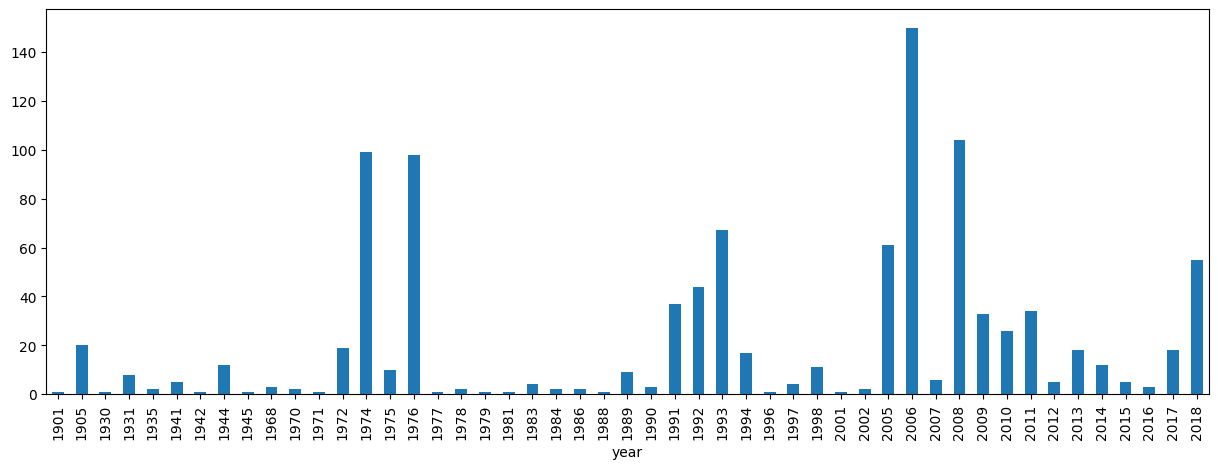

In [ ]:
#Plotting number of records by year
plt.figure(figsize=(15,5))
df_BR['year'].value_counts().sort_index().plot(kind="bar")
plt.show()

# **Malaria trends according to *Plasmodium* species – Brazil, 2003-2022**


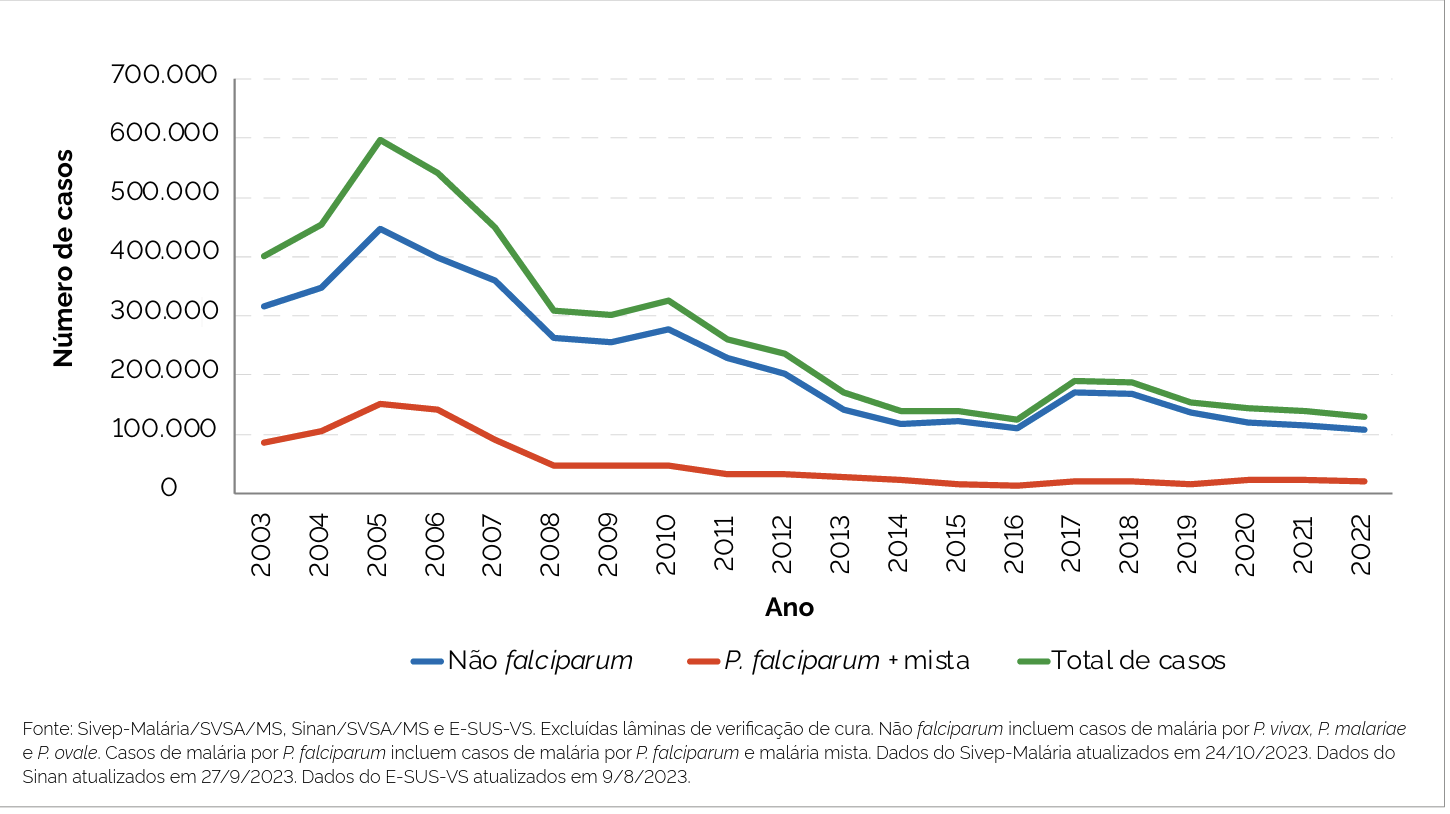

Between 2003 and 2022, malaria cases went down from over 400.000 to under 130.000, a reduction of 67.9%. There were peaks of malaria cases recorded near 2005 and 2017, which correspond to peak of records of Anopheles mosquitoes in GBIF.

**Source:** Brasil. Ministério da Saúde. Secretaria de Vigilância em Saúde e Ambiente. Boletim Epidemiológico. Volume 55, N.º 1, 18 jan. 2024.
[Disponível aqui](https://www.gov.br/saude/pt-br/centrais-de-conteudo/publicacoes/boletins/epidemiologicos/edicoes/2024/boletim-epidemiologico-volume-55-no-01/)

In [ ]:
#Geographic distribution of species
f1 = folium.Figure(width=1000, height=500)
m_1 = folium.Map(location=[-14.2350, -51.9253], tiles='openstreetmap', zoom_start=4).add_to(f1)

#Dictionary of colors by species
species_colors = {
    "Anopheles darlingi": "red",
    "Anopheles gambiae": "gray",
    "Anopheles albimanus": "pink",
    "Anopheles albitarsis": "orange",
    "Anopheles nuneztovari": "purple",
    "Anopheles marajoara": "green",
    "Anopheles aquasalis": "blue",
    "Anopheles funestus": "darkred"
}


#Add to the map with different colors by species
for idx, row in df_BR.iterrows():
    species = row['species']
    color = species_colors.get(species, "black")  #use black if not found in dictionary
    Marker(
        location=[row['decimalLatitude'], row['decimalLongitude']],
        popup=species,
        icon=folium.Icon(color=color)
    ).add_to(m_1)

#Legend on the bottom-left corner
legend_html = """
<div style="position: fixed;
     bottom: 50px; left: 50px; width: 250px; height: aut;
     border:2px solid grey; z-index:9999; font-size:14px;
     background-color:white; padding:10px;">
     <b>Legenda:</b><br>
     <i style="color:red;" class="fa fa-map-marker"></i> Anopheles darlingi<br>
    <i style="color:gray;" class="fa fa-map-marker"></i> Anopheles gambiae<br>
    <i style="color:pink;" class="fa fa-map-marker"></i> Anopheles albimanus<br>
    <i style="color:orange;" class="fa fa-map-marker"></i> Anopheles albitarsis<br>
    <i style="color:purple;" class="fa fa-map-marker"></i> Anopheles nuneztovari<br>
    <i style="color:green;" class="fa fa-map-marker"></i> Anopheles marajoara<br>
    <i style="color:blue;" class="fa fa-map-marker"></i> Anopheles aquasalis<br>
    <i style="color:darkred;" class="fa fa-map-marker"></i> Anopheles funestus<br>

</div>
"""
m_1.get_root().html.add_child(folium.Element(legend_html))
m_1

In [ ]:
f2 = folium.Figure(width=1000, height=500)
m_2 = folium.Map(location=[-14.2350, -51.9253], tiles='cartodbpositron', zoom_start=4).add_to(f2)

# add points to the map
mc = MarkerCluster()
for idx, row in df_BR.iterrows():
    if not math.isnan(row['decimalLongitude']) and not math.isnan(row['decimalLatitude']):
        mc.add_child(Marker([row['decimalLatitude'], row['decimalLongitude']]))
m_2.add_child(mc)

# Display the map
m_2

# **Map of Malaria incidence – Brazil, 2022**

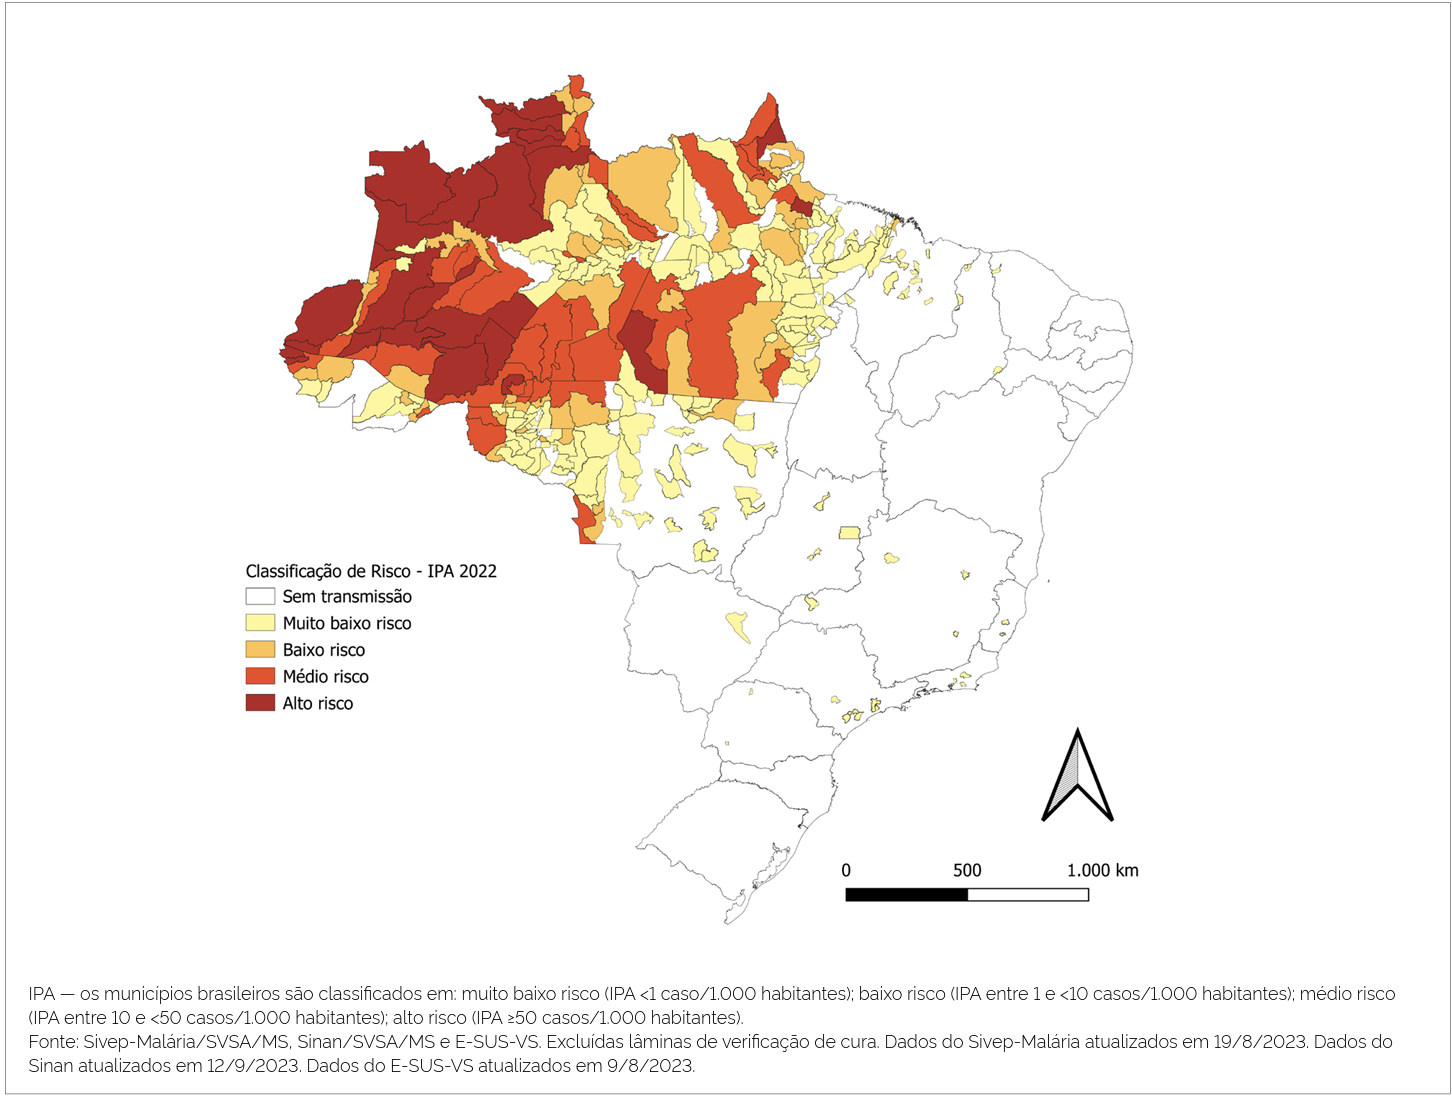


According to the Boletim Epidemiológico do Ministério da Saúde do Brasil (January 2024), 99,9% of malaria cases occur in the Amazon region. In 2021, 33 municipalities (out of 5570) concentrated 80% of national cases.

**Source:** Brasil. Ministério da Saúde. Secretaria de Vigilância em Saúde e Ambiente. Boletim Epidemiológico. Volume 55, N.º 1, 18 jan. 2024.
[Disponível aqui](https://www.gov.br/saude/pt-br/centrais-de-conteudo/publicacoes/boletins/epidemiologicos/edicoes/2024/boletim-epidemiologico-volume-55-no-01/)

Brazil:
* Species diversity correlates to highest malaria incidence;
* Number of records in GBIF peak after peaks of malaria incidence in the previous years;
* African Anopheles species found on the eastern coast.
* A. darlingi is prevalent in the northwestern region, as in the literature, but records are few near the coast.
* A. albitarsis is the mhighest-recorded species, prevalent in most of the country.

Mozambique:
* Most results are from the exact same coordinates in Inhambane, suggesting a big surveillance project in the region.
* Records in the North of the country are moslty A. gambiae, and A. merus.
* All species are present in the South of the country.

General conclusions:
* Mosquito prevalence and species diversity do not always correlate with malaria incidence.
* Big surveillance projects can cause bias, with certain regions having much more records than others.

![image1.jpeg](
kd6zfMkre1l97Pnd/+CZX7LJ+RtK8TEHqD4yvuf8AyLXtPw88AeHPhb4I0z4d+DLF7bStGsktbCB5mkKRoMAFmJLH3Nb2FBxn9KeoXpnNehgcoy7Lr/VqUYX35Ulf1sjnrYzE4q3tZuVu7b/MTYCclRQI1HYflTqK9SyOcQopOSM0nlrnOBTqKLIBNq5ztH5UFFP8I/KloosgE2D+6v5UnlrnOB+VOopgIq7RjNLRRQAUUUUAFFFFABRRRQAUUUUAFFFFABRRRQAUUUUAFFFFABRRRQAUUUUAFFFFABRRRQAUUUUAFFFFABRRRQAUEA8GiigD5i/4KofFr4i/Br9mgeKvhf4wuNE1STxHZW322z2+YIn8wsoLAgZ2jt2r86z+3P8Atkyjb/w0b4jI9d0P/wAbr9A/+CufgjxZ4y/ZTNj4L8Lajq91B4msLiW10uye4lEYMgLbIwWIBYdB3r8yh8Fvjafl/wCFJ+M//CTvf/jVfrPAOH4cr4ObzHl5r6czSdrLa5/O3i1ieMsPmFNZQpcrTvyptXv1t5HYH9ub9sgnI/aM8RD/AL8//G6n039uj9siPU7VZP2ivELqbqJWRjDhgXAIP7v0riP+FK/Gv/oinjP/AMJO9/8AjVT6X8EPjbNq1nEvwU8ZAteRYJ8KXoA+depMXFfXZvguCI4Co6DjzcrtZq97aW+Z+dcN4/xOnnFGOKU/ZuS5rppWur302sfst8fvj94Y/Zp+BOs/GrxnbXF5Do9grW+nWYzcaldyFY7e0hX+KWaZ0iQd2cV5h8If+CjPwt1T9mLwn8ev2lHsvh1qviPxJqPhqfw4LyXUTFrllNeRT2ELxQh53/0GcriMFtoABYqDN+09+xz4l/a9+J/gex+Ivje/0j4beDIm1qOw8L+IbvTtWvfEisqWkzTQBDFBbRmV12yFmllBIAjBbhP2af8AgnT8TPgV8ZbDUtU8Yadrfgrwf4s8Y+JfBEOra5eX2qf2hrItRHJdSzxks6eZq4eTzHb/AEpMbstt/nqfL7Rn9kYe/sYn1B8J/i38PPjz8PtP+Kfwp8TJq+hamJPsd6kMkRZo5HikRo5VV43SRHRkdQyshBAIrwz4v/8ABRvwT8L/ANsBv2Zr3TbK20rw54S/4SH4jeLtbmvraDRreVilrFBss5IbmaVlOFaaPONqb5MoO6/Y++DnxN/Z9+EmgfB/xrFot5FYaKbvV9csNSmea8126u7i5vyIXgUCAyTb0kL72LsDGm0FvJ/2kP2LP2jviVqHxO8X/Dvx5pVtqfjLxh4bmtNP/wCEmv8ASReeHtMtgG06W/s4WuLCSS5luZhJArkZUZ+ZtsN2Zsekx/8ABRP9jqT4en4mzfGeK30pfEi+H5EvdHvYLyLVHgNxHZvZyQrcJK8OJEUxgurIVzvXN+z/AG7/ANlS9+KGn/BqL4qxp4i1S4gtbWzn0m8ijF3NCJ4rOSd4RFDdNEQ4tpHWbBHyV89/skf8E0fjV8KfippPxF+NXiLw7qEdr8UdW8Z3Nrb+JtV1mZZX0O10jTIRdampnnMES3RaSR/vGNlAyUTnr7/gmd+2V4r/AGj9G+IfjT4naHdaTovxT1HxTNq8/wARdfuJdRheC+GnRjRWRdOs2tZZrTPl7zIICwkQ5V03awH1J4//AG7P2aPh38JYPjZq/wAQkl0K+j1ZtLuLTT7mZ746bFcS3gjRIixCJaTnfjadgwTuXNb9l39r/Q/2o9N8P6x4d0aPTDqvw/sfE2qaNftdR6hpf2yaaKCN4pbaNShNtdDfuDEw5CFGDn5hl/4Jv/tueL/gBY/CDxrrnwwsF8J/ATUfAnhPT9L1fULiK71G9FtBdajd3ElmjRie1glUiOJjE1y/+t619R/s9/Anx14B+KfxD+LXj5tGivvFkWiWOj2mi3Us8dhp9hp6osBaSKPOLue+cYGCjoTgkqH3FqaPhT9tP9mXxx8arj9nvwt8Vba68W21zd2p0/7DcpFNcWv/AB9QQ3LRiCeaHB8yKORnTa24DacX/D3xun8Q/tOeJ/2fNP8ADqtb+FvB+k6xf619rOTcX1xexpa+XtwNsdn5hbdnEqjb3Pzn+z7+xp+2R8H/AI9az8a7lvh1brPp+pzX+i6B4p1SPTPF+tXEyNHqs9hNaPDok+zzjK9oZmmadtxI5r2v4VfBz4wfDn4wfEP4o3kHh7UX+IPj2zuZWOqTxvpuhW2kW1rFGg+znzZxcxTyeWSibbgnzMjaUruw31PaaKRBhQKWqAKKKKADAznFFFFABRRRQAUUUUAFFFFABRRRQAUUUUAFFFFABRRRQAUUUUAFFFFABRRRQB+K3/B7b/yZF8IP+yqyf+m25oo/4Pbf+TIvhB/2VWT/ANNtzRQB9M/8Emv+Ch37BXwb/YB8DfDH4uftnfC3wx4k0i41mHVtB1/x5YWl5ZyHWL1tksMsqvG21gcMAcEV9If8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9d/4Jif9JDfgr/4czTP/j9FFAB/w9d/4Jif9JDfgr/4czTP/j9H/D13/gmJ/wBJDfgr/wCHM0z/AOP0UUAH/D13/gmJ/wBJDfgr/wCHM0z/AOP0f8PXf+CYn/SQ34K/+HM0z/4/RRQAf8PXf+CYn/SQ34K/+HM0z/4/R/w9d/4Jif8ASQ34K/8AhzNM/wDj9FFAB/w9d/4Jif8ASQ34K/8AhzNM/wDj9H/D13/gmJ/0kN+Cv/hzNM/+P0UUAH/D13/gmJ/0kN+Cv/hzNM/+P0f8PXf+CYn/AEkN+Cv/AIczTP8A4/RRQAf8PXf+CYn/AEkN+Cv/AIczTP8A4/R/w9e/4Jh/9JC/gt/4czS//j9FFADW/wCCrP8AwTBbr/wUK+Cv/hzNL/8Aj9Mb/gqj/wAEvjyf+ChHwU/8OZpf/wAfoopqTRnKlTluhP8Ah6j/AMEvAcH/AIKEfBT/AMOZpf8A8fp3/D1P/gl+Pu/8FCPgp/4czS//AI/RRT5pFQw1HsSD/gq5/wAEwx0/4KG/BX/w5mmf/H6P+Hrv/BMT/pIb8Ff/AA5mmf8Ax+iipKD/AIeu/wDBMT/pIb8Ff/DmaZ/8fo/4euf8Ew/+khvwV/8ADmaZ/wDH6KKAD/h65/wTDHT/AIKFfBX/AMObpf8A8fo/4evf8Ewv+khnwV/8Odpf/wAfoooAP+Hrn/BMP/pIb8Ff/DmaZ/8AH6P+Hrn/AATD/wCkhvwV/wDDmaZ/8foooAP+Hrn/AATD/wCkhvwV/wDDmaZ/8fo/4et/8Ewv+khXwV/8Obpf/wAfoooAP+Hrv/BMT/pIb8Ff/DmaZ/8AH6P+Hrv/AATE/wCkhvwV/wDDmaZ/8foooAP+Hrv/AATE/wCkhvwV/wDDmaZ/8fo/4eu/8ExP+khvwV/8OZpn/wAfoooAP+Hrv/BMT/pIb8Ff/DmaZ/8AH6P+Hrv/AATE/wCkhvwV/wDDmaZ/8foooAP+Hrv/AATE/wCkhvwV/wDDmaZ/8fo/4eu/8ExP+khvwV/8OZpn/wAfoooAP+Hrv/BMT/pIb8Ff/DmaZ/8AH6P+Hrv/AATE/wCkhvwV/wDDmaZ/8foooAP+Hrv/AATE/wCkhvwV/wDDmaZ/8fo/4eu/8ExP+khvwV/8OZpn/wAfoooAP+Hrv/BMT/pIb8Ff/DmaZ/8AH6P+Hrv/AATE/wCkhvwV/wDDmaZ/8foooAP+Hrv/AATE/wCkhvwV/wDDmaZ/8fo/4eu/8ExP+khvwV/8OZpn/wAfoooAP+Hrv/BMT/pIb8Ff/DmaZ/8AH6P+Hrv/AATE/wCkhvwV/wDDmaZ/8foooAP+Hrv/AATE/wCkhvwV/wDDmaZ/8fo/4eu/8ExP+khvwV/8OZpn/wAfoooAP+Hrv/BMT/pIb8Ff/DmaZ/8AH6P+Hrv/AATE/wCkhvwV/wDDmaZ/8foooAP+Hrv/AATE/wCkhvwV/wDDmaZ/8fo/4eu/8ExP+khvwV/8OZpn/wAfoooAP+Hrv/BMT/pIb8Ff/DmaZ/8AH6P+Hrv/AATE/wCkhvwV/wDDmaZ/8foooA/JP/g7i/a8/ZT/AGpP2Q/hd4S/Zr/aS8DeP9U034jyXeoab4M8S2eqz21v/Z86ebJHDIzIm5lXcQBlgO9FFFAH/9k=)

**Source:** Sinka, M.E., Bangs, M.J., Manguin, S. et al. A global map of dominant malaria vectors. Parasites Vectors 5, 69 (2012). https://doi.org/10.1186/1756-3305-5-69